# QFF 2026 Phase 2 ? PS-O1 Weighted Max-Cut

QAOA-based optimization of a locked six-vertex weighted graph.

This notebook reproduces Processor D validation, Bell-state verification,
five-seed QAOA benchmarking, and submission figures.


In [7]:
from pathlib import Path
import sys
import subprocess

ROOT = Path.cwd()
assert (ROOT / "qff_phase2.py").exists(), "Run from the starter-pack directory"

def run(script):
    subprocess.run([sys.executable, script], cwd=ROOT, check=True)


## 1. Validate Processor D and benchmark routing

In [8]:
run("phase2_d_benchmark.py")

## 2. Bell-state verification

In [9]:
run("phase2_bell_test.py")

## 3. Five-seed QAOA Max-Cut experiment

In [10]:
run("phase2_qaoa.py")

## 4. Generate comparison figures

In [11]:
run("phase2_figures.py")

## 5. Display results

,processor,mode,mean_cut_mean,mean_cut_std,approximation_ratio_mean,approximation_ratio_std,p_opt_mean,p_opt_std,r_best_mean,r_best_std,cx_mean,cx_std,depth_mean,depth_std,swaps_mean,swaps_std,cx_overhead_mean,cx_overhead_std
0,Processor B,Ideal,15.804004,1.209031,0.718364,0.054956,0.051514,0.056316,1.0,0.0,21.0,0.0,37.0,0.0,1.0,0.0,3.0,0.0
1,Processor B,Noisy,15.528857,1.105547,0.705857,0.050252,0.049219,0.049590,1.0,0.0,21.0,0.0,37.0,0.0,1.0,0.0,3.0,0.0
2,Processor D,Ideal,15.787744,1.173147,0.717625,0.053325,0.049365,0.056314,1.0,0.0,18.0,0.0,29.0,0.0,0.0,0.0,0.0,0.0
3,Processor D,Noisy,15.530078,1.080185,0.705913,0.049099,0.047705,0.048741,1.0,0.0,18.0,0.0,29.0,0.0,0.0,0.0,0.0,0.0


,pair_type,processor,pair,noisy,shots,pair_distance,XX,XX_se,YY,YY_se,ZZ,ZZ_se,cx,fidelity,fidelity_se
0,adjacent,Processor D,0-2,False,4096,1,1.000000,0.000000,-1.000000,0.000000,1.000000,0.000000,1,1.000000,0.000000
1,adjacent,Processor D,0-2,True,4096,1,0.945801,0.005074,-0.952148,0.004776,0.955078,0.004631,1,0.963257,0.002092
2,farthest,Processor D,0-1,False,4096,2,1.000000,0.000000,-1.000000,0.000000,1.000000,0.000000,4,1.000000,0.000000
3,farthest,Processor D,0-1,True,4096,2,0.944336,0.005140,-0.934082,0.005579,0.938477,0.005396,4,0.954224,0.002327


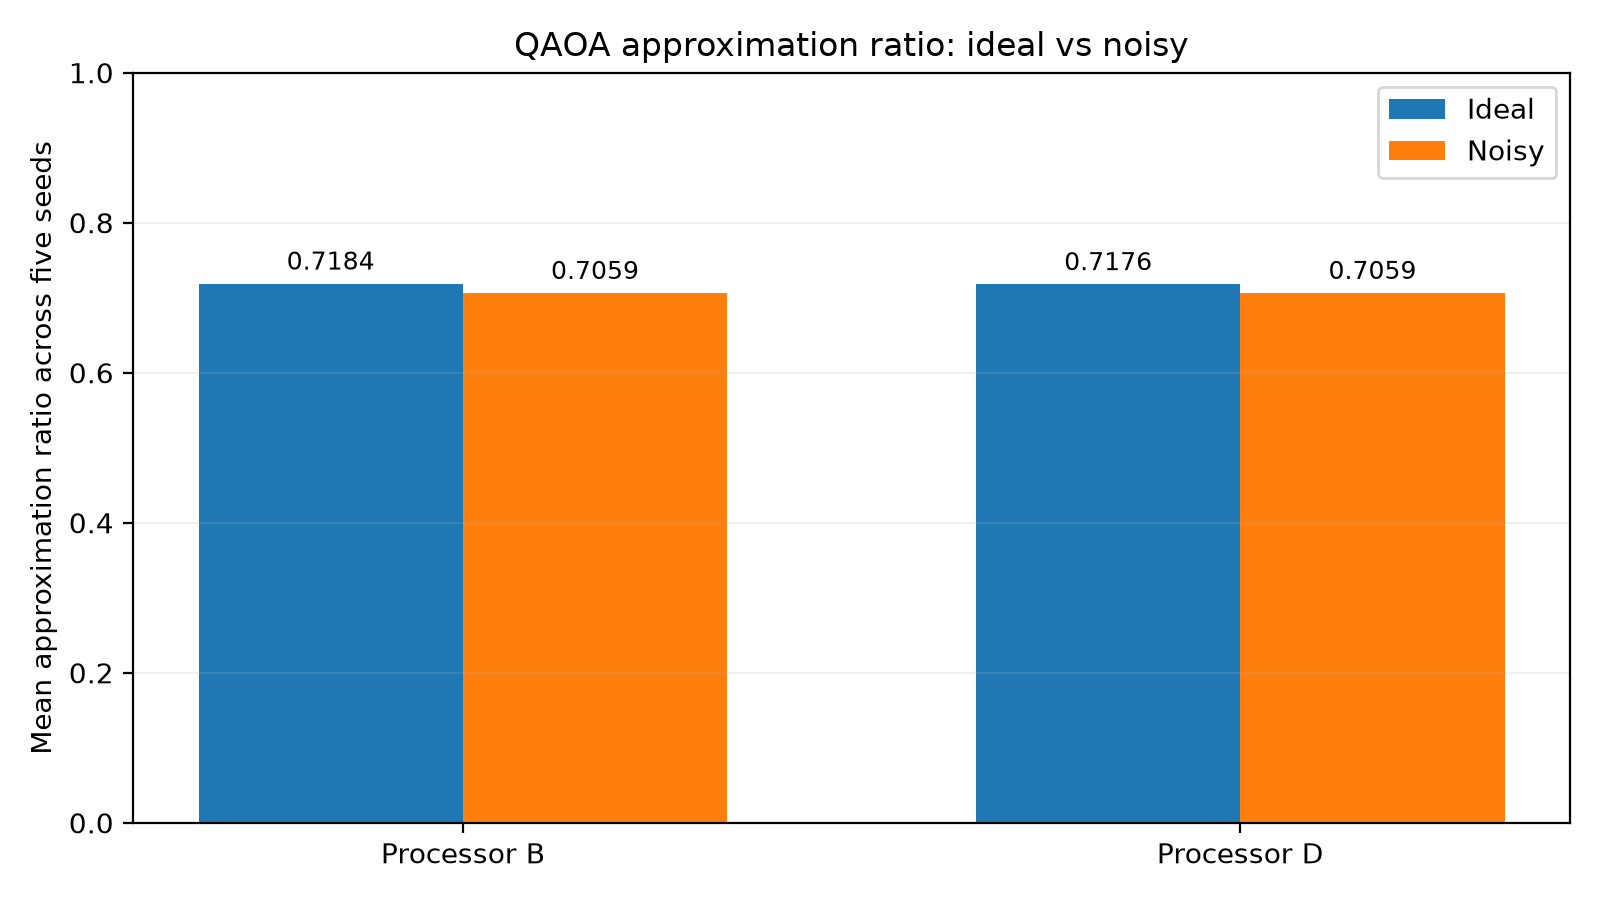

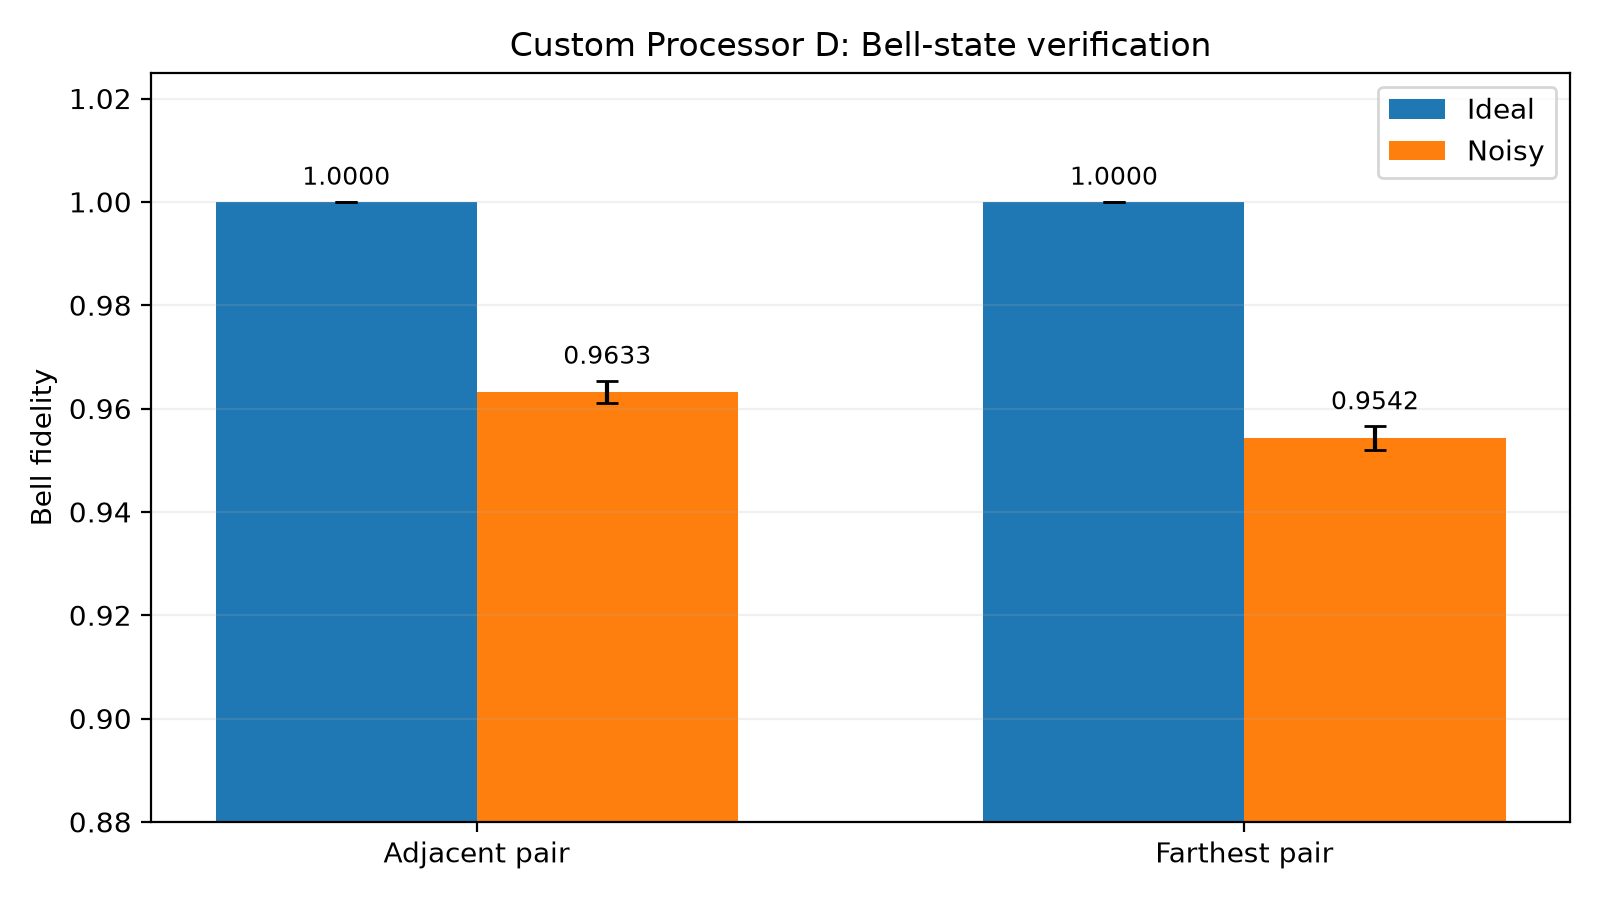

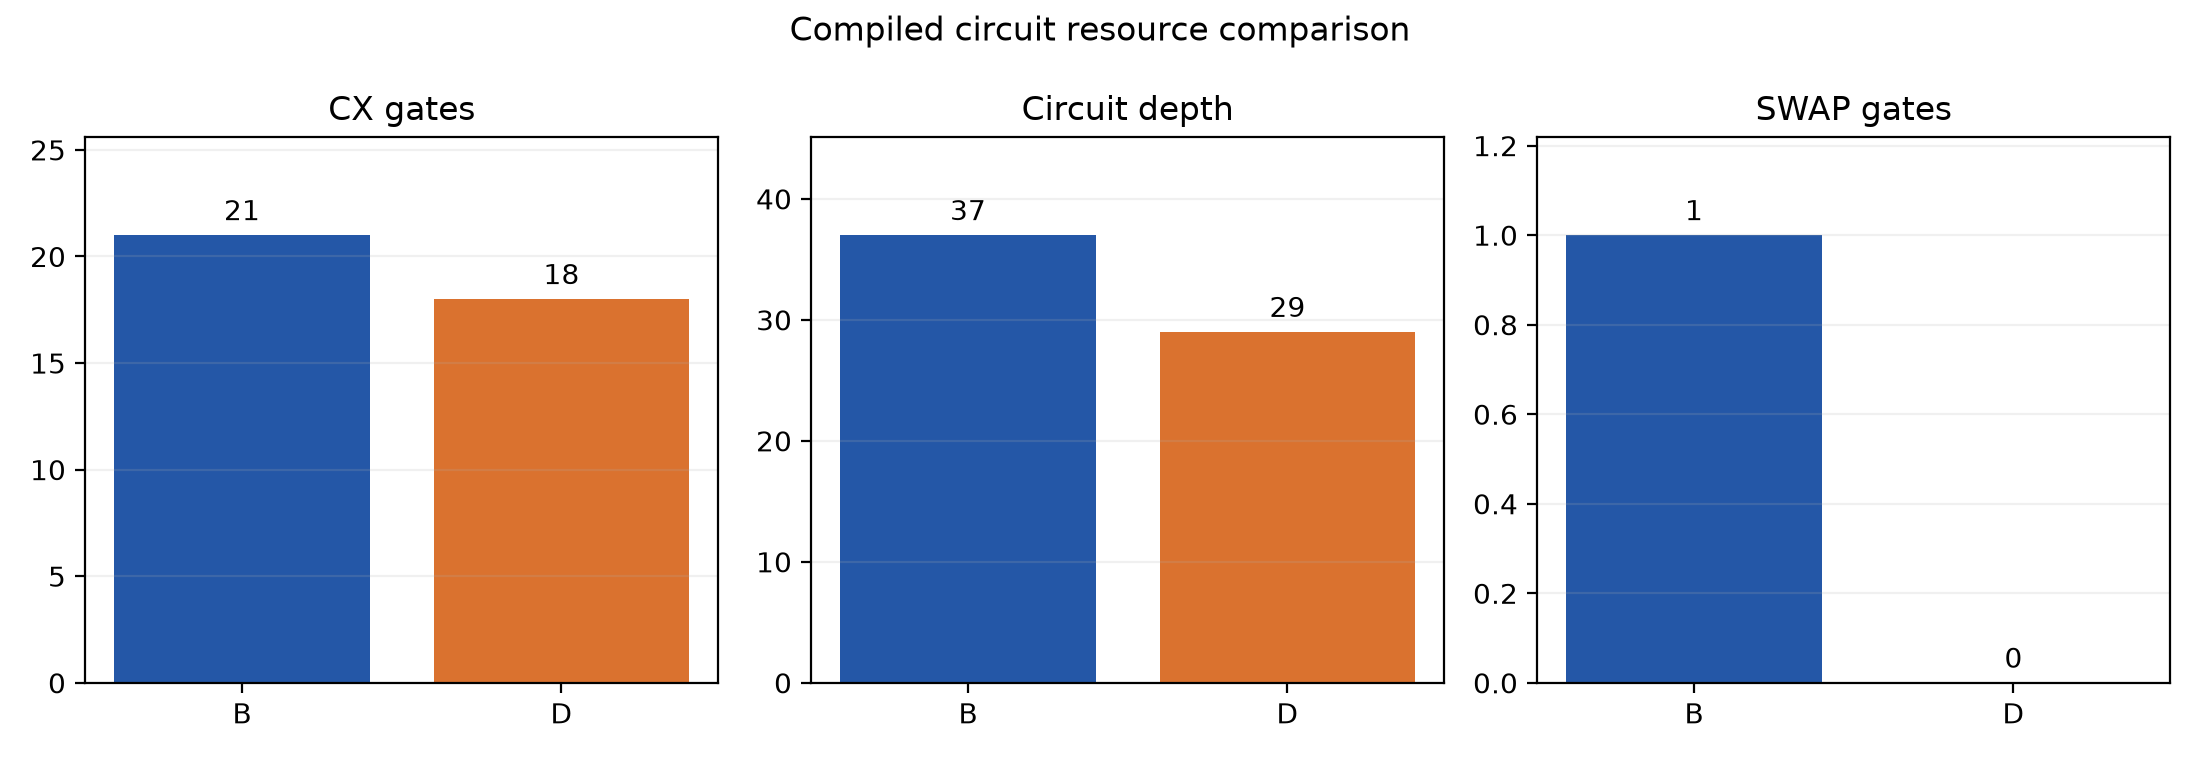

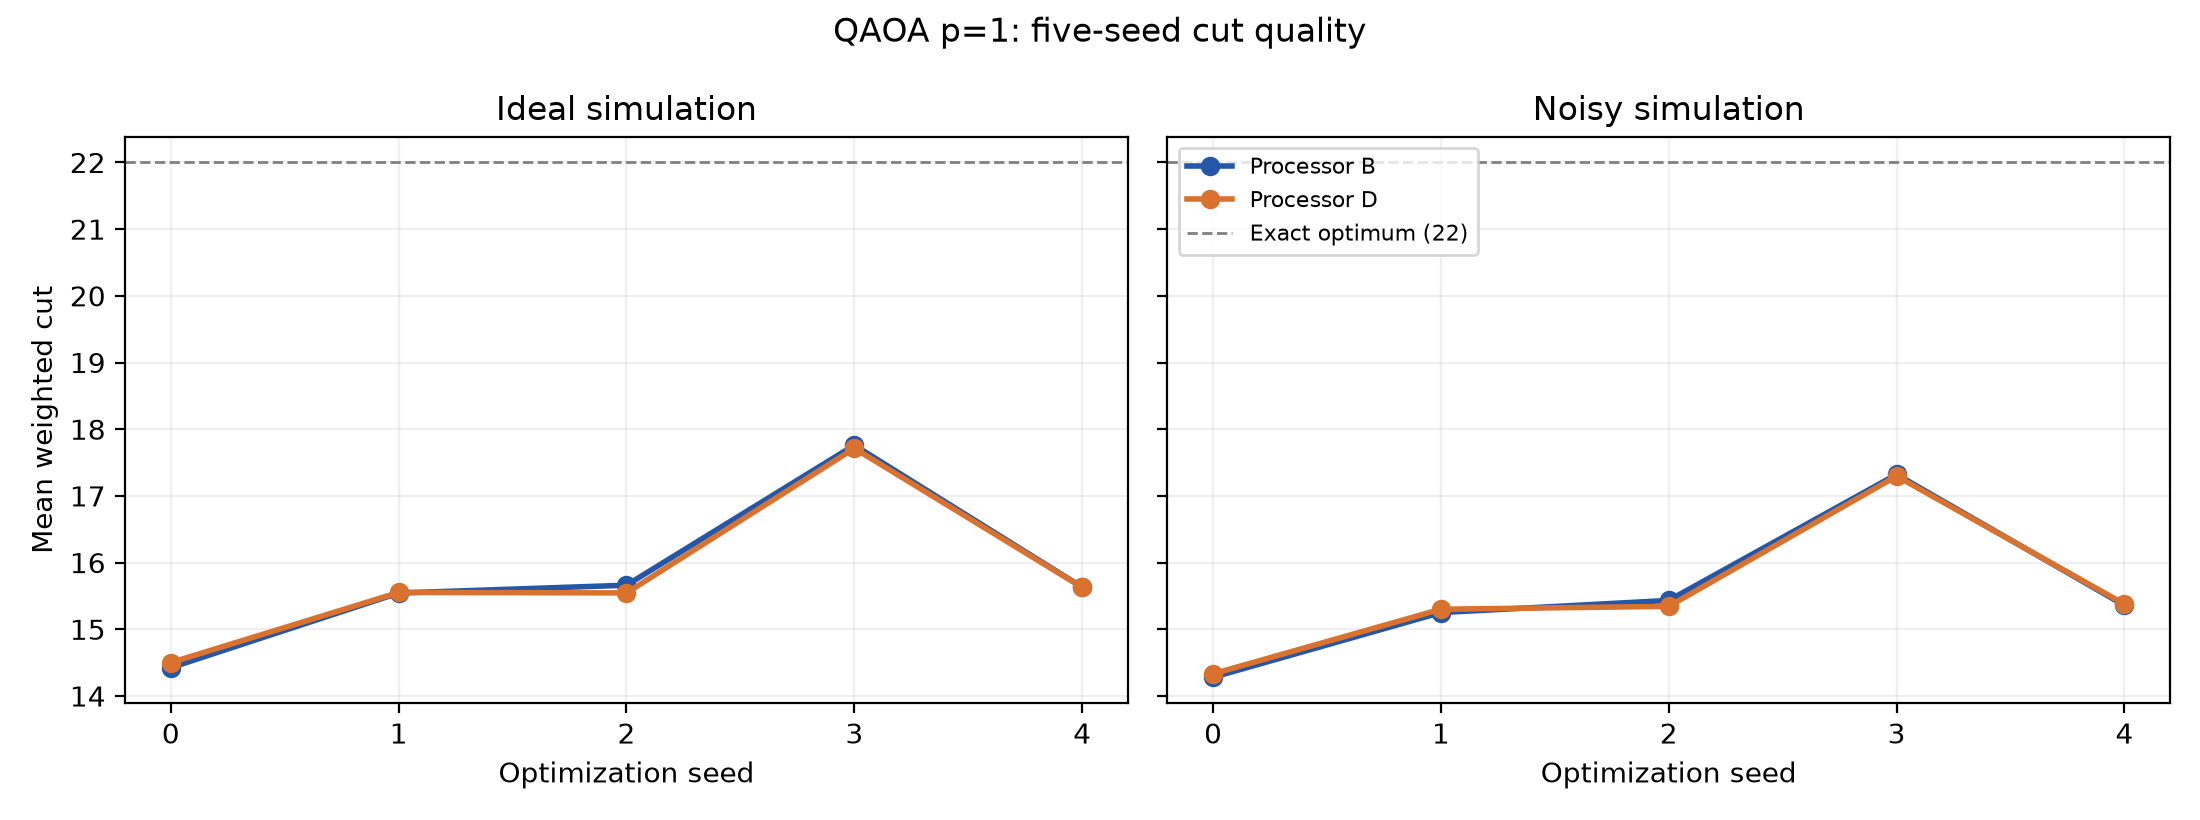

In [12]:
import pandas as pd
from IPython.display import display, Image

tables = ROOT / "results" / "tables"
display(pd.read_csv(tables / "qaoa_summary.csv"))
display(pd.read_csv(tables / "bell.csv"))

for name in [
    "approximation_ratio.png",
    "bell_fidelity.png",
    "processor_resources.png",
    "qaoa_mean_cut_by_seed.png"
]:
    display(Image(filename=str(ROOT / "results" / "figures" / name)))
